![Python Banner](../../Image/05_04_doubleML.png)


# 4.1. Double ML: Bias, Orthogonalization

**Double/debiased machine learning (DML)** provides valid causal inference when flexible ML methods are used to control for high-dimensional confounding. Standard ML estimators are ill-suited to causal questions: regularization shrinks coefficients toward zero (introducing bias in $\hat{\theta}$), and fitting nuisance functions on the same data used for causal estimation causes overfitting bias. DML corrects both problems by combining **Neyman-orthogonal scores**, **sample splitting**, and **cross-fitting**, yielding $\sqrt{n}$-consistent, asymptotically normal estimates of causal parameters.

This notebook is organized in two parts:

- **Part A — Synthetic data:** builds intuition by simulating the partially linear model and comparing three estimators side-by-side — naive ML (biased), orthogonalized ML without sample splitting (overfitting bias), and full DML with cross-fitting (valid inference).
- **Part B — Real-world application:** applies DML to the 401(k) eligibility dataset in `Data/data_401k.csv`, covering a train–test split, causal estimation with `PartiallyLinearDML`, holdout validation of nuisance predictions, and SHAP interpretation of heterogeneous treatment effects with `LinearDML.explain`.


## Overview

ML models predict well but produce biased causal estimates because regularization (for example, a shallow random forest or a penalized regression) distorts the coefficients we care about. The table below summarizes the three challenges DML addresses and how it addresses each one.

| Challenge | Why it matters | DML's response |
|-----------|---------------|----------------|
| Regularization bias | ML shrinks nuisance fits, which contaminates $\hat{\theta}$ | Neyman-orthogonal scores (partialling-out or IV-type) make $\hat{\theta}$ insensitive to first-order nuisance errors |
| Overfitting bias | Using the same data for ML nuisances and for estimating $\theta$ inflates apparent fit | Sample splitting: train nuisances on one fold, estimate $\theta$ on another |
| High-dimensional confounders | Classical OLS breaks down when $p \gg n$ or relationships are non-linear | Flexible learners (random forests, gradient boosting, lasso) estimate $g_0(X)$ and $m_0(X)$ |

Cross-fitting combines both halves of the sample split by rotating roles across $K$ folds, so no observations are wasted.


## The Partially Linear Regression (PLR) Model

Both parts of this notebook use the **partially linear regression (PLR)** model, which separates the linear treatment effect $\theta_0$ from the nonparametric confounding functions $g_0$ and $m_0$:

$$Y = D\,\theta_0 + g_0(X) + \zeta, \quad \mathbb{E}(\zeta \mid D, X) = 0$$

$$D = m_0(X) + V, \quad \mathbb{E}(V \mid X) = 0$$

| Symbol | Role |
|--------|------|
| $Y$ | Outcome variable |
| $D$ | Treatment variable |
| $X$ | High-dimensional confounders |
| $\theta_0$ | Causal parameter (ATE) |
| $g_0(X),\, m_0(X)$ | Nuisance functions estimated by ML |
| $\zeta,\, V$ | Stochastic errors |


## Implementation in Python

Throughout this notebook the causal estimators come from **PyCausalML**. Part A writes the three scores explicitly — non-orthogonal, IV-type, and partialling-out — so the source of the bias is visible. The cross-fitted partialling-out estimator is the same construction as `PartiallyLinearDML`. Part B calls `PartiallyLinearDML` and `LinearDML` directly on `Data/data_401k.csv`.


## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
data_dir = root / "Data"
if not data_dir.is_dir():
    raise FileNotFoundError(
        "The Data directory was not found. It should sit next to pyproject.toml."
    )

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")
print("Data directory:", data_dir)


PyCausalML ready.
Data directory: /home/zia207/Github/PyCausalML/Data


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import Lasso, LassoCV, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    mean_squared_error,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from pycausalml import (
    CausalForestDML,
    InteractiveRegressionDML,
    KernelDML,
    LinearDML,
    NonParamDML,
    PartiallyLinearDML,
    SparseLinearDML,
    explain_cate,
)
from pycausalml.interpretation import plot_cate_hist

plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


## Part A: Diagnosing Bias with Synthetic Data

Part A uses Monte Carlo simulation to make the bias problems visible. We draw replications of the partially linear model from Chernozhukov et al. (2018) and compare the distribution of the rescaled estimator $(\hat{\theta} - \theta_0) / \hat{\text{se}}$ against $\mathcal{N}(0,1)$ under three approaches. A valid estimator produces a histogram that matches the standard normal; deviations expose regularization or overfitting bias.

The data-generating process is:

$$y_i = \theta_0\, d_i + g_0(x_i) + \zeta_i, \quad \zeta_i \sim \mathcal{N}(0,1)$$

$$d_i = m_0(x_i) + v_i, \quad v_i \sim \mathcal{N}(0,1)$$

Covariates $x_i \sim \mathcal{N}(0, \Sigma)$ with $\Sigma_{kj} = 0.7^{|j-k|}$. The true causal parameter is $\theta_0 = 0.5$. Nuisance functions:

$$m_0(x_i) = x_{i,1} + \frac{1}{4}\frac{\exp(x_{i,3})}{1 + \exp(x_{i,3})}$$

$$g_0(x_i) = \frac{\exp(x_{i,1})}{1 + \exp(x_{i,1})} + \frac{1}{4}x_{i,3}$$

Each replication draws $n = 500$ observations with $p = 20$ covariates. The extra coordinates are pure noise, which is what makes a regularized forest shrink $g_0$. The Monte Carlo uses 30 replications so the notebook finishes in one pass; increase `n_rep` for a tighter histogram.

### A.1 Generate Simulated Data


In [3]:
def make_plr_ccddhnr2018(n_obs, dim_x, alpha, rng):
    """Partially linear DGP from Chernozhukov et al. (2018)."""
    index = np.arange(dim_x)
    cov = 0.7 ** np.abs(index[:, None] - index[None, :])
    x = rng.multivariate_normal(np.zeros(dim_x), cov, size=n_obs)
    m0 = x[:, 0] + 0.25 / (1.0 + np.exp(-x[:, 2]))
    g0 = 1.0 / (1.0 + np.exp(-x[:, 0])) + 0.25 * x[:, 2]
    d = m0 + rng.normal(size=n_obs)
    y = alpha * d + g0 + rng.normal(size=n_obs)
    columns = [f"X{j + 1}" for j in range(dim_x)]
    frame = pd.DataFrame(x, columns=columns)
    frame["d"] = d
    frame["y"] = y
    return frame


def forest(seed):
    return RandomForestRegressor(
        n_estimators=40,
        max_depth=4,
        min_samples_leaf=5,
        random_state=seed,
        n_jobs=1,
    )


def _predict_nuisance(X, target, n_splits, seed, cross_fit):
    if not cross_fit:
        model = forest(seed)
        model.fit(X, target)
        return model.predict(X)
    pred = np.zeros(len(target))
    splitter = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for fold, (tr, te) in enumerate(splitter.split(X)):
        model = forest(seed + fold)
        model.fit(X[tr], target[tr])
        pred[te] = model.predict(X[te])
    return pred


def plr_estimate(X, d, y, score, cross_fit, seed, n_splits=2):
    """Return (theta, se) for one PLR score.

    score='nonorth' uses only the outcome nuisance and a single sample split.
    score='iv' residualizes Y with g(X) and instruments D with D - m(X).
    score='partial' residualizes both Y and D (the PartiallyLinearDML score).
    """
    if score == "nonorth":
        splitter = KFold(n_splits=2, shuffle=True, random_state=seed)
        tr, te = next(splitter.split(X))
        model = forest(seed)
        model.fit(X[tr], y[tr])
        g_hat = model.predict(X[te])
        d_te, y_te = d[te], y[te]
        theta = float(np.dot(d_te, y_te - g_hat) / np.dot(d_te, d_te))
        resid = d_te * (y_te - g_hat - theta * d_te)
        se = float(np.std(resid, ddof=1) / (np.sqrt(len(te)) * np.mean(d_te ** 2)))
        return theta, se

    g_hat = _predict_nuisance(X, y, n_splits, seed, cross_fit)
    m_hat = _predict_nuisance(X, d, n_splits, seed + 17, cross_fit)
    if score == "iv":
        v_hat = d - m_hat
        u_hat = y - g_hat
        denom = float(np.dot(v_hat, d))
        theta = float(np.dot(v_hat, u_hat) / denom)
        psi = v_hat * (u_hat - theta * d) / np.mean(v_hat * d)
    elif score == "partial":
        y_res = y - g_hat
        d_res = d - m_hat
        denom = float(np.dot(d_res, d_res))
        theta = float(np.dot(d_res, y_res) / denom)
        psi = d_res * (y_res - theta * d_res) / np.mean(d_res ** 2)
    else:
        raise ValueError(score)
    se = float(np.std(psi, ddof=1) / np.sqrt(len(psi)))
    return theta, se


def replicate(datasets, score, cross_fit, seed):
    theta = np.empty(len(datasets))
    se = np.empty(len(datasets))
    for i, frame in enumerate(datasets):
        x_cols = [c for c in frame.columns if c.startswith("X")]
        theta[i], se[i] = plr_estimate(
            frame[x_cols].to_numpy(),
            frame["d"].to_numpy(),
            frame["y"].to_numpy(),
            score=score,
            cross_fit=cross_fit,
            seed=seed + i,
        )
    return theta, se


rng = np.random.default_rng(1234)
n_rep = 30
n_obs = 500
n_vars = 20
alpha = 0.5
datasets = [make_plr_ccddhnr2018(n_obs, n_vars, alpha, rng) for _ in range(n_rep)]
datasets[0].head()


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X13,X14,X15,X16,X17,X18,X19,X20,d,y
0,-0.835221,-0.124267,1.589069,1.751438,2.626595,1.851129,0.103141,-0.405645,-0.611519,1.110242,...,0.640197,1.773906,0.411589,0.989881,0.943173,-0.314249,1.190312,1.350330,-1.305642,-0.350469
1,0.599646,-0.523910,0.190086,1.121859,1.092862,1.040196,0.541563,-0.088291,-0.261876,-0.498918,...,-0.415038,-1.116630,-1.143365,0.725883,-0.465223,0.225297,0.459585,0.555681,2.087219,2.418215
2,0.311204,0.041244,1.065855,-0.400307,-0.244778,-0.061993,-0.033064,-0.300112,-0.386585,1.415881,...,2.543828,0.693934,1.331406,0.146785,1.826707,1.174719,0.879243,1.194841,2.572813,2.947322
3,-0.971602,-0.108555,-0.178463,0.421183,-0.075388,-0.320963,-1.289692,0.795079,0.023707,-0.631630,...,-0.352978,-0.856797,0.091880,0.261878,0.563516,0.428166,-0.743977,-0.727835,-1.455845,-1.966873
4,-0.554568,0.171370,0.753571,-0.197624,-0.242975,-0.180769,-0.165187,-2.000960,-1.769597,-1.104878,...,0.185810,-0.467623,-0.966863,-0.906213,-1.165086,-0.325888,0.965086,2.065493,1.152327,0.809282


## A.2 Define Shared Learners

Both nuisance functions ($g_0$ and $m_0$) are estimated with a random forest (40 trees, max depth 4). The same specification is rebuilt for every replication so the hyperparameters stay fixed. `PartiallyLinearDML` uses the same forest family through `model_y="rf"`.


In [4]:
print(forest(0))


RandomForestRegressor(max_depth=4, min_samples_leaf=5, n_estimators=40,
                      n_jobs=1, random_state=0)


## A.3 Approach 1 — Naive ML (Non-Orthogonal Score)

A **naive** estimator splits the sample in two, fits $\hat{g}_0(X)$ with ML on one half, then uses the other half to compute:

$$\hat{\theta}_0 = \Bigl(\tfrac{1}{n}\sum_{i \in I} D_i^2\Bigr)^{-1}
  \tfrac{1}{n}\sum_{i \in I} D_i\bigl(Y_i - \hat{g}_0(X_i)\bigr)$$

This uses a **non-orthogonal score**. Regularization bias from estimating $g_0$ with ML does not vanish; $\sqrt{n}(\hat{\theta}_0 - \theta_0)$ does not stay bounded.

### A.3.1 Define Non-Orthogonal Score

The score below uses only $\hat{g}(X)$ to residualize $Y$, ignoring $D$'s dependence on $X$. The moment condition is therefore not orthogonal.

### A.3.2 Fit Naive ML Over Replications


In [5]:
theta_nonorth, se_nonorth = replicate(datasets, score="nonorth", cross_fit=False, seed=1111)
print("Mean theta:", round(float(np.mean(theta_nonorth)), 4))


Mean theta: 0.2824


### A.3.3 Plot Distribution — Non-Orthogonal

Under valid inference, $(\hat{\theta} - \theta_0) / \hat{\text{se}}$ should follow $\mathcal{N}(0,1)$. For the naive estimator it does not: the histogram is shifted and spread, revealing **regularization bias** from the forest's shrinkage of $g_0(X)$.


In [6]:
def plot_t_hist(values, title, color, label):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    grid = np.linspace(-6, 6, 400)
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    ax.hist(values, bins=30, density=True, alpha=0.35, color=color, edgecolor=color, label=label)
    ax.plot(grid, stats.norm.pdf(grid), color="black", lw=1.2, label="N(0,1)")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlim(-6, 6)
    ax.set_xlabel("Rescaled estimate")
    ax.set_ylabel("Density")
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    return fig


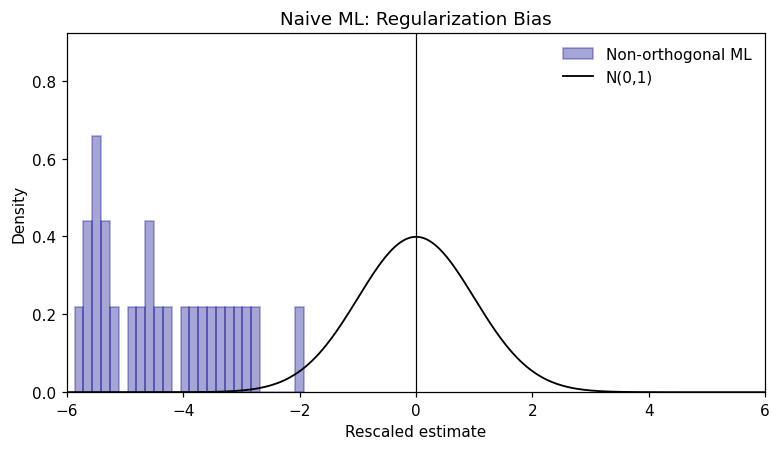

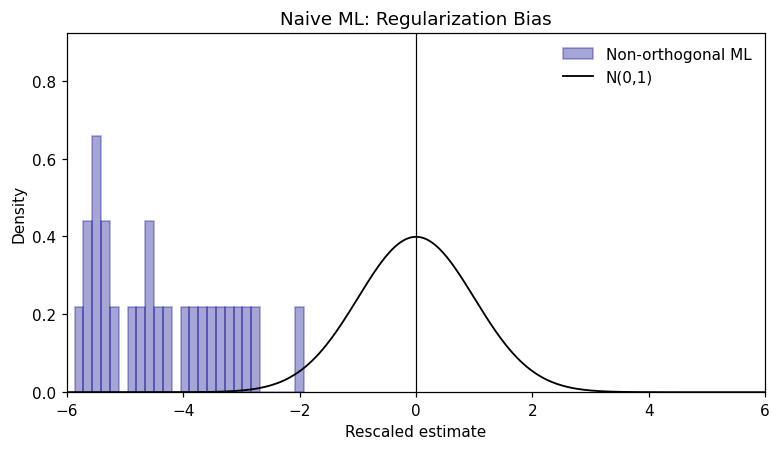

In [7]:
t_nonorth = (theta_nonorth - alpha) / se_nonorth
plot_t_hist(t_nonorth, "Naive ML: Regularization Bias", "darkblue", "Non-orthogonal ML")


## A.4 Approach 2 — Orthogonalized ML, No Sample Splitting

Orthogonalization removes the leading regularization bias by partialling $X$ out of $D$ as well. Let $\hat{V} = D - \hat{m}(X)$ and use the IV-type score:

$$\check{\theta}_0 = \Bigl(\tfrac{1}{n}\sum_{i \in I} \hat{V}_i D_i\Bigr)^{-1}
  \tfrac{1}{n}\sum_{i \in I} \hat{V}_i\bigl(Y_i - \hat{g}_0(X_i)\bigr)$$

With nuisances and the final estimate computed on the **same data**, overfitting bias is not eliminated by sample splitting.

### A.4.1 Fit IV-Type Score, No Sample Splitting


In [8]:
theta_orth_nosplit, se_orth_nosplit = replicate(datasets, score="iv", cross_fit=False, seed=2222)
print("Mean theta:", round(float(np.nanmean(theta_orth_nosplit)), 4))


Mean theta: 0.4167


### A.4.2 Plot Distribution — Orthogonal, No Sample Splitting


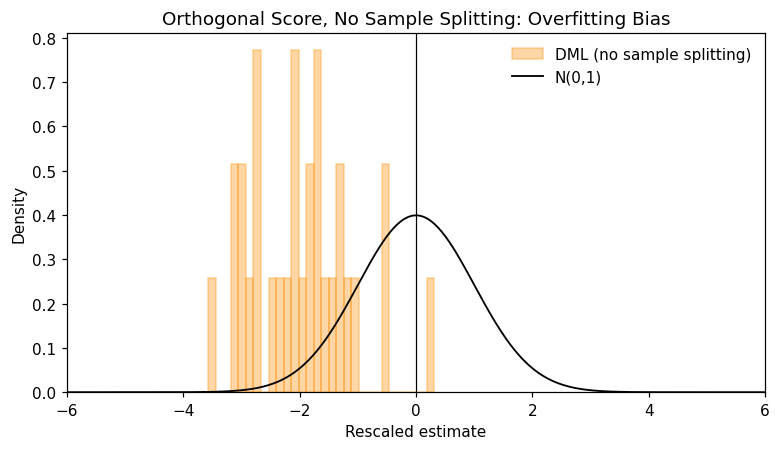

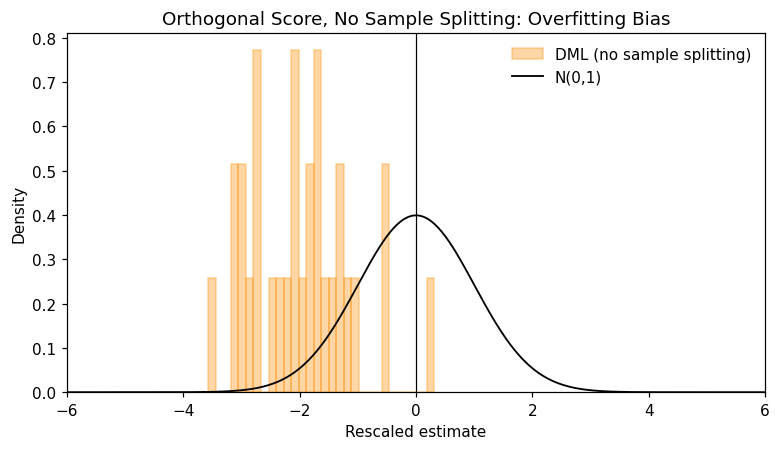

In [9]:
t_orth_nosplit = (theta_orth_nosplit - alpha) / se_orth_nosplit
plot_t_hist(
    t_orth_nosplit,
    "Orthogonal Score, No Sample Splitting: Overfitting Bias",
    "darkorange",
    "DML (no sample splitting)",
)


Even with an orthogonal score, omitting sample splitting allows overfitting bias to persist. Extreme or non-finite t-values (filtered in the histogram) are a characteristic symptom.

## A.5 Approach 3 — Full DML with Cross-Fitting (IV-Type Score)

Cross-fitting completes the fix. With two folds, nuisances are trained on one fold and $\theta$ estimated on the held-out fold; the roles are then swapped and the estimates combined. This eliminates both regularization bias (orthogonal score) and overfitting bias (sample splitting) while using all observations.

### A.5.1 Fit DML with Cross-Fitting (IV-Type)


In [10]:
theta_dml, se_dml = replicate(datasets, score="iv", cross_fit=True, seed=3333)
print("Mean theta:", round(float(np.mean(theta_dml)), 4))


Mean theta: 0.4888


### A.5.2 Plot Distribution — DML with Cross-Fitting


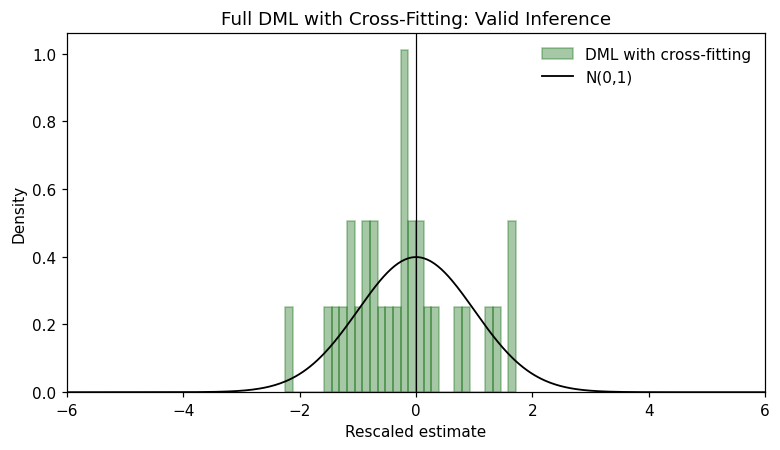

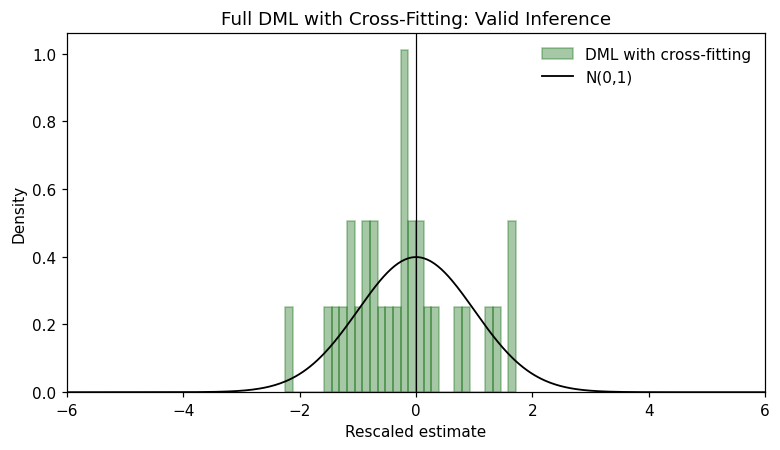

In [11]:
t_dml = (theta_dml - alpha) / se_dml
plot_t_hist(t_dml, "Full DML with Cross-Fitting: Valid Inference", "darkgreen", "DML with cross-fitting")


The rescaled estimates now sit much closer to $\mathcal{N}(0,1)$, confirming that combining an orthogonal score with cross-fitting restores valid inference.

## A.6 Comparison: All Three IV-Type Approaches


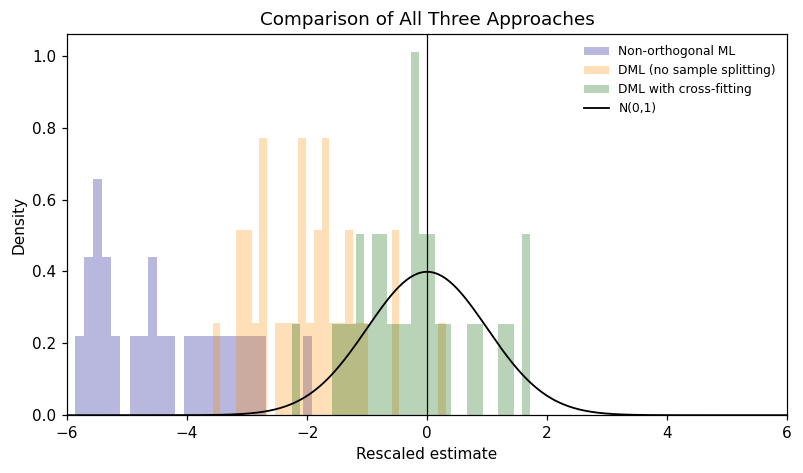

In [12]:
fig, ax = plt.subplots(figsize=(7.4, 4.4))
grid = np.linspace(-6, 6, 400)
specs = [
    (t_nonorth, "darkblue", "Non-orthogonal ML"),
    (t_orth_nosplit, "darkorange", "DML (no sample splitting)"),
    (t_dml, "darkgreen", "DML with cross-fitting"),
]
for values, color, label in specs:
    finite = np.asarray(values, dtype=float)
    finite = finite[np.isfinite(finite)]
    ax.hist(finite, bins=30, density=True, alpha=0.28, color=color, label=label)
ax.plot(grid, stats.norm.pdf(grid), color="black", lw=1.2, label="N(0,1)")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-6, 6)
ax.set_xlabel("Rescaled estimate")
ax.set_ylabel("Density")
ax.set_title("Comparison of All Three Approaches")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()


The three histograms make the progression concrete: naive ML (blue) is shifted and spread; orthogonal without splitting (orange) is better but still distorted; full DML with cross-fitting (green) is the one that lines up with $\mathcal{N}(0,1)$.

## A.7 Partialling-Out Score

The **partialling-out** score is the most common choice in practice. It uses $\ell_0(X) = \mathbb{E}[Y|X]$ and $m_0(X) = \mathbb{E}[D|X]$ directly. The orthogonal moment condition is:

$$\psi(W;\,\theta,\eta) := \bigl[Y - \ell(X) - \theta(D - m(X))\bigr](D - m(X))$$

`PartiallyLinearDML` solves this score. We repeat the no-splitting versus cross-fitting comparison to confirm that the result holds independently of which orthogonal score is used.

### A.7.1 Partialling-Out, No Sample Splitting


In [13]:
theta_po_nosplit, se_po_nosplit = replicate(datasets, score="partial", cross_fit=False, seed=4444)
print("Mean theta:", round(float(np.mean(theta_po_nosplit)), 4))


Mean theta: 0.4833


### A.7.2 Partialling-Out with Cross-Fitting


In [14]:
theta_dml_po, se_dml_po = replicate(datasets, score="partial", cross_fit=True, seed=5555)
# The same score, called through PyCausalML on the first replication.
frame0 = datasets[0]
x_cols = [c for c in frame0.columns if c.startswith("X")]
package_fit = PartiallyLinearDML(
    discrete_treatment=False, n_splits=2, model_y="rf", n_estimators=40, random_state=5555,
)
package_fit.fit(frame0[x_cols], frame0["d"], frame0["y"], feature_names=x_cols)
print("Manual cross-fit mean theta:", round(float(np.mean(theta_dml_po)), 4))
print("PartiallyLinearDML on replication 1:", package_fit.average_treatment_effect())


Manual cross-fit mean theta: 0.4751
PartiallyLinearDML on replication 1: {'estimate': 0.39925797346729136, 'std.err': 0.04753551277103456, 'ci_lower': 0.3060900804494199, 'ci_upper': 0.49242586648516284}


### A.7.3 Plot Distribution — Partialling-Out with Cross-Fitting


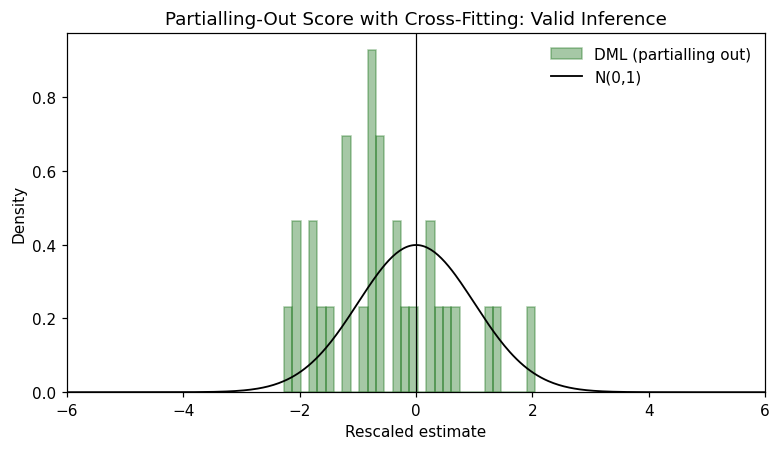

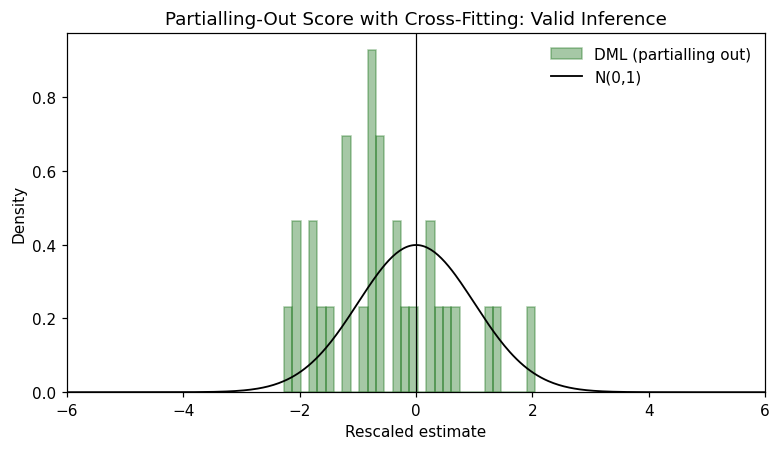

In [15]:
t_dml_po = (theta_dml_po - alpha) / se_dml_po
plot_t_hist(
    t_dml_po,
    "Partialling-Out Score with Cross-Fitting: Valid Inference",
    "darkgreen",
    "DML (partialling out)",
)


### A.7.4 Comparison: Partialling-Out vs IV-Type (with Cross-Fitting)


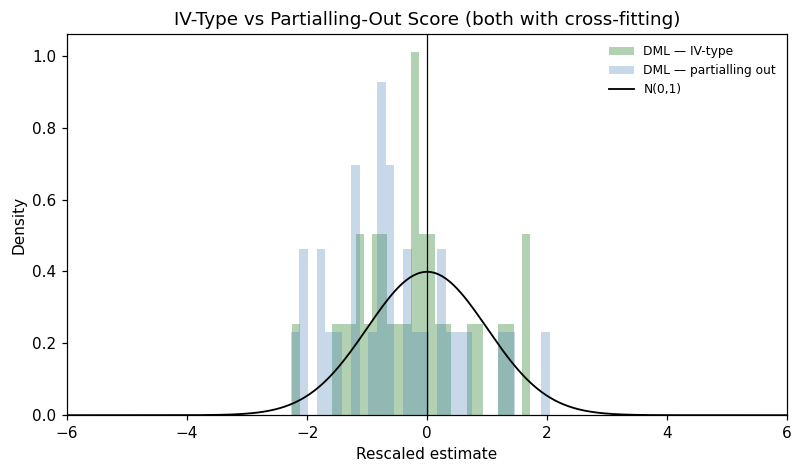

In [16]:
fig, ax = plt.subplots(figsize=(7.4, 4.4))
grid = np.linspace(-6, 6, 400)
for values, color, label in [
    (t_dml, "darkgreen", "DML — IV-type"),
    (t_dml_po, "steelblue", "DML — partialling out"),
]:
    finite = np.asarray(values, dtype=float)
    finite = finite[np.isfinite(finite)]
    ax.hist(finite, bins=30, density=True, alpha=0.3, color=color, label=label)
ax.plot(grid, stats.norm.pdf(grid), color="black", lw=1.2, label="N(0,1)")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-6, 6)
ax.set_xlabel("Rescaled estimate")
ax.set_ylabel("Density")
ax.set_title("IV-Type vs Partialling-Out Score (both with cross-fitting)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()


Both scores achieve approximately valid inference when combined with cross-fitting. The two distributions are close in practice, which supports using whichever score is computationally simpler for a given problem.

### A.7.5 Summary Table — Simulation Results


In [17]:
names = [
    "Non-orthogonal ML",
    "IV-type, no sample splitting",
    "IV-type with cross-fitting",
    "Partialling-out, no sample splitting",
    "Partialling-out with cross-fitting",
]
estimates = [theta_nonorth, theta_orth_nosplit, theta_dml, theta_po_nosplit, theta_dml_po]
summary_sim = pd.DataFrame([
    {
        "Approach": name,
        "Mean estimate": round(float(np.nanmean(est)), 4),
        "SD": round(float(np.nanstd(est, ddof=1)), 4),
        "Bias": round(float(np.nanmean(est) - alpha), 4),
    }
    for name, est in zip(names, estimates)
])
print(f"Simulation results across {n_rep} replications (true theta_0 = {alpha})")
summary_sim


Simulation results across 30 replications (true theta_0 = 0.5)


,Approach,Mean estimate,SD,Bias
0,Non-orthogonal ML,0.2824,0.0551,-0.2176
1,"IV-type, no sample splitting",0.4167,0.0369,-0.0833
2,IV-type with cross-fitting,0.4888,0.0490,-0.0112
3,"Partialling-out, no sample splitting",0.4833,0.0443,-0.0167
4,Partialling-out with cross-fitting,0.4751,0.0475,-0.0249


## Part B: Real-World Application — 401(k) Eligibility and Net Financial Assets

Part B applies DML to the **401(k) dataset** (Chernozhukov et al., 2020), stored as `Data/data_401k.csv`, to estimate the average causal effect of employer-sponsored 401(k) eligibility (`e401`) on net total financial assets (`net_tfa`), controlling for age, income, education, family structure, and other background variables.

The workflow has four stages: (1) an 80/20 stratified train–test split; (2) causal estimation with `PartiallyLinearDML` on the training fold; (3) out-of-sample validation of the nuisance models on the held-out test fold; and (4) SHAP interpretation of treatment-effect heterogeneity with `LinearDML`. Formal PLR inference applies to the training sample. The test fold is used for predictive checks of the nuisance regressions.

## B.1 Load and Inspect the 401(k) Data


In [18]:
df_401k = pd.read_csv(data_dir / "data_401k.csv")
print("Dimensions:", df_401k.shape)
df_401k.head()


Dimensions: (9915, 11)


,net_tfa,age,inc,educ,fsize,marr,twoearn,db,pira,hown,e401
0,0,47,6765,8,2,0,0,0,0,1,0
1,1015,36,28452,16,1,0,0,0,0,1,0
2,-2000,37,3300,12,6,0,0,1,0,0,0
3,15000,58,52590,16,2,1,1,0,0,1,0
4,0,32,21804,11,1,0,0,0,0,1,0


## B.2 Outcome, Treatment, Covariates, and Train–Test Split

The split is stratified on `e401` (80% train / 20% test) so both folds retain similar treatment prevalence.


In [19]:
x_cols_401k = ["age", "inc", "fsize", "educ", "db", "marr", "twoearn", "pira", "hown"]
X_401k = df_401k[x_cols_401k].to_numpy(dtype=float)
y_401k = df_401k["net_tfa"].to_numpy(dtype=float)
t_401k = df_401k["e401"].to_numpy(dtype=int)

rng_split = np.random.default_rng(3141)
train_parts = []
for arm in (0, 1):
    pool = np.flatnonzero(t_401k == arm)
    take = max(1, int(np.floor(0.8 * len(pool))))
    train_parts.append(rng_split.choice(pool, size=take, replace=False))
train_idx = np.sort(np.concatenate(train_parts))
test_idx = np.setdiff1d(np.arange(len(t_401k)), train_idx)
X_tr, X_te = X_401k[train_idx], X_401k[test_idx]
y_tr, y_te = y_401k[train_idx], y_401k[test_idx]
t_tr, t_te = t_401k[train_idx], t_401k[test_idx]
print(
    "Train n =", len(train_idx),
    "| Test n =", len(test_idx),
    "| mean(e401) train =", round(float(t_tr.mean()), 3),
    "test =", round(float(t_te.mean()), 3),
)


Train n = 7931 | Test n = 1984 | mean(e401) train = 0.371 test = 0.371


## B.3 Specify Learners

Both nuisance models use a **random forest** (40 trees, max depth 4). Random forests suit this sample: the covariate set is moderate and several relationships are unlikely to be linear. `model_y="rf"` selects that learner inside PyCausalML.


In [20]:
print("Nuisance learner: random forest via PartiallyLinearDML(model_y='rf')")


Nuisance learner: random forest via PartiallyLinearDML(model_y='rf')


## B.4 Fit DML on the Training Set

We fit the PLR with the partialling-out score and cross-fitting on the training data `(X_tr, t_tr, y_tr)`.


In [21]:
fit_401k = PartiallyLinearDML(
    discrete_treatment=True,
    n_splits=3,
    model_y="rf",
    n_estimators=40,
    random_state=3142,
)
fit_401k.fit(X_tr, t_tr, y_tr, feature_names=x_cols_401k)
fit_401k.average_treatment_effect()


{'estimate': 8878.397799393653,
 'std.err': 1518.4719733355994,
 'ci_lower': 5902.247420122413,
 'ci_upper': 11854.548178664892}

## B.5 Statistical Inference (training sample)

### B.5.1 Coefficient Summary


In [22]:
summary_401k = fit_401k.average_treatment_effect()
print("Effect of 401(k) eligibility on net financial assets (training fit):")
for key, value in summary_401k.items():
    print(f"  {key}: {value:,.2f}")


Effect of 401(k) eligibility on net financial assets (training fit):
  estimate: 8,878.40
  std.err: 1,518.47
  ci_lower: 5,902.25
  ci_upper: 11,854.55


### B.5.2 Confidence Interval


In [23]:
ci_lo, ci_hi = fit_401k.confidence_interval(level=0.95)
print("95% confidence interval (training sample):")
print(f"  [{ci_lo:,.2f}, {ci_hi:,.2f}]")


95% confidence interval (training sample):
  [5,902.25, 11,854.55]


### B.5.3 Visualize the Estimate


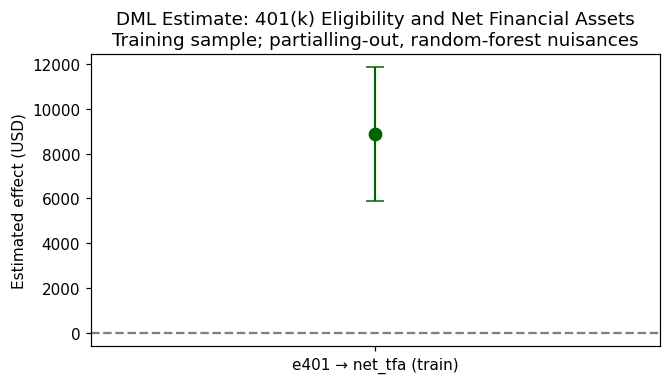

In [24]:
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.errorbar(
    [0], [summary_401k["estimate"]],
    yerr=[[summary_401k["estimate"] - ci_lo], [ci_hi - summary_401k["estimate"]]],
    fmt="o", color="darkgreen", ms=8, capsize=6, lw=1.4,
)
ax.axhline(0, color="grey", ls="--")
ax.set_xticks([0])
ax.set_xticklabels(["e401 → net_tfa (train)"])
ax.set_ylabel("Estimated effect (USD)")
ax.set_title("DML Estimate: 401(k) Eligibility and Net Financial Assets\nTraining sample; partialling-out, random-forest nuisances")
fig.tight_layout()


### B.5.4 Interpretation

The estimated coefficient on `e401` is the PLR average treatment effect for the training subsample, under the standard PLR assumptions (unconfoundedness, overlap, and nuisance fits that converge fast enough). A positive estimate is consistent with 401(k) eligibility raising net financial assets, in line with Chernozhukov et al. (2020).

## B.6 Holdout Validation of Nuisance Models

To check that the nuisance models generalize beyond the training fold, we refit random forests on the training data only and evaluate them on the held-out test set. We report RMSE for the outcome regression $\hat{\ell}(X) \approx \mathbb{E}[Y|X]$ and the Brier score for the treatment propensity $\hat{m}(X) \approx \mathbb{E}[D|X]$. Lower values indicate better out-of-sample nuisance fit. This is a predictive sanity check — it does not replace the PLR assumptions, but a severely poor fit would signal that the nuisance models are misspecified.


In [25]:
rf_y = RandomForestRegressor(n_estimators=80, max_depth=5, min_samples_leaf=2, random_state=1, n_jobs=1)
rf_d = RandomForestClassifier(n_estimators=80, max_depth=5, min_samples_leaf=2, random_state=1, n_jobs=1)
rf_y.fit(X_tr, y_tr)
rf_d.fit(X_tr, t_tr)
y_hat = rf_y.predict(X_te)
p_hat = rf_d.predict_proba(X_te)[:, 1]
rmse_y = float(np.sqrt(mean_squared_error(y_te, y_hat)))
brier_d = float(brier_score_loss(t_te, p_hat))
validation_tbl = pd.DataFrame({
    "Metric": ["RMSE of Y (net_tfa)", "Brier score for D (e401)"],
    "Value": [round(rmse_y, 2), round(brier_d, 4)],
})
validation_tbl


,Metric,Value
0,RMSE of Y (net_tfa),48105.74
1,Brier score for D (e401),0.20


## B.7 SHAP Interpretation of Treatment Effect Heterogeneity

`PartiallyLinearDML` estimates a single scalar $\hat{\theta}$, which is not a function of $X$ and therefore cannot be explained by SHAP. To explore which covariates drive heterogeneity, we fit `LinearDML` on the training fold (random-forest first stage, OLS on the residual-on-residual design). This produces a CATE prediction $\hat{\tau}(X)$ that varies with $X$. Permutation SHAP is computed with `explain_cate` on a subsample of the test rows.


ATE from the linear CATE: {'estimate': 8183.038050910903, 'std.err': 1515.9678873491396, 'ci_lower': 5211.795589987316, 'ci_upper': 11154.28051183449}


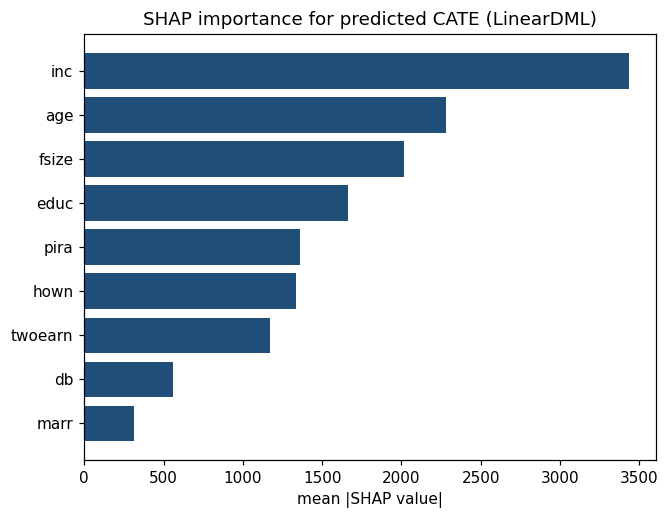

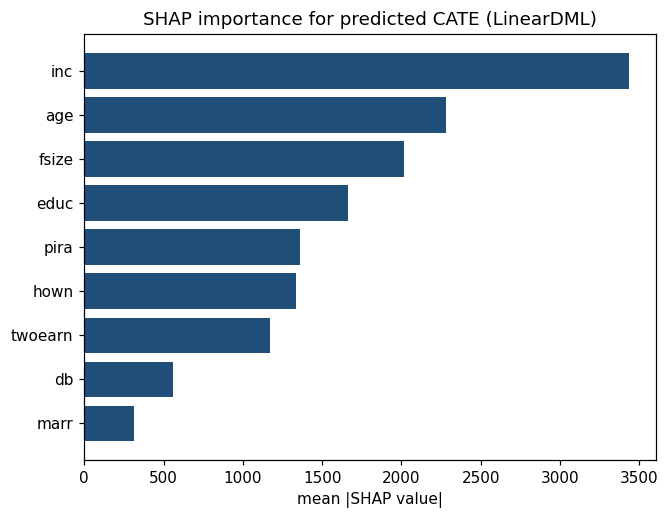

In [26]:
ldml_401k = LinearDML(
    discrete_treatment=True, n_splits=3, model_y="rf", n_estimators=40, random_state=3143,
)
ldml_401k.fit(X_tr, t_tr, y_tr, feature_names=x_cols_401k)
explanation = explain_cate(
    ldml_401k, X_te, feature_names=x_cols_401k,
    max_samples=48, n_permutations=8, random_state=3143,
)
print("ATE from the linear CATE:", ldml_401k.average_treatment_effect())
explanation.plot_importance(title="SHAP importance for predicted CATE (LinearDML)")


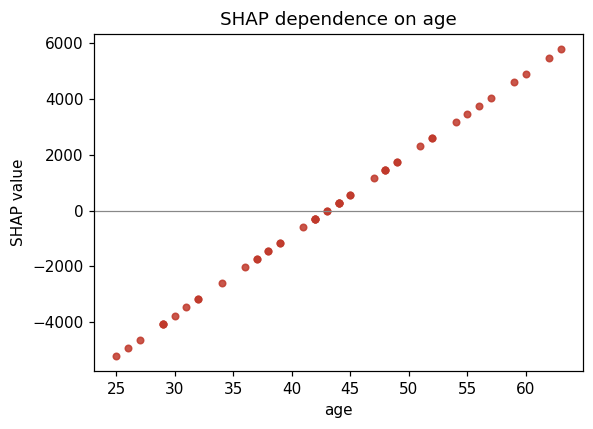

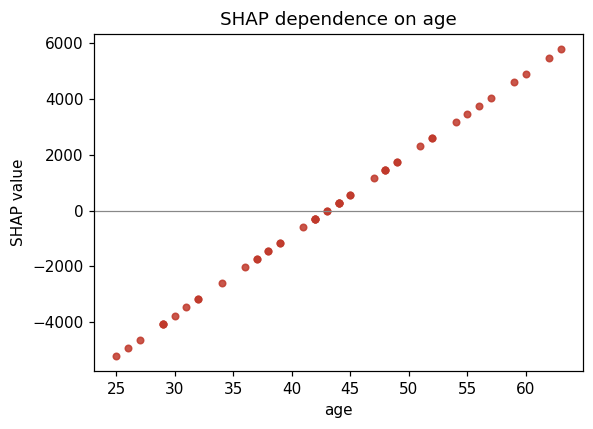

In [27]:
explanation.plot_dependence("age", title="SHAP dependence on age")


**Reading the plots.** SHAP values here are contributions to $\hat{\tau}(X)$ from `LinearDML` — a descriptive heterogeneity model, not the same object as the PLR scalar $\hat{\theta}$ in B.4–B.5. Use them to explore which covariates are associated with larger or smaller estimated treatment effects under this specification.


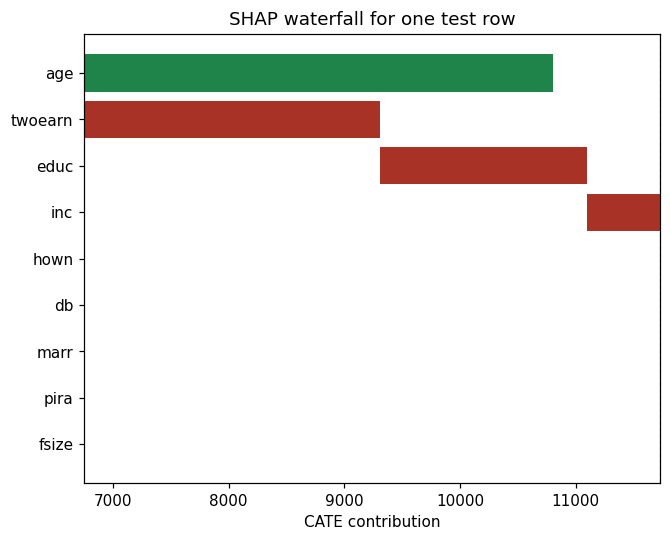

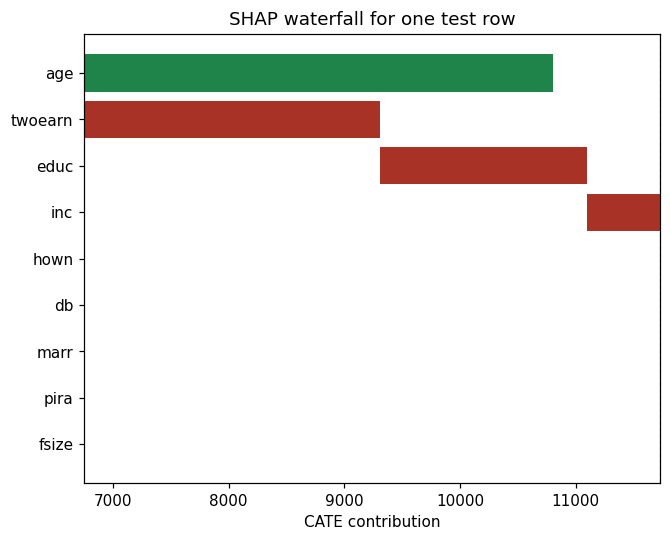

In [28]:
explanation.plot_waterfall(row=0, title="SHAP waterfall for one test row")


---

# Summary

| Step | Lesson |
|------|--------|
| **Naive ML** | Non-orthogonal score + ML → regularization bias, invalid inference |
| **Orthogonalization** | IV-type or partialling-out score removes leading bias |
| **No sample splitting** | Same data for ML and $\hat{\theta}$ → overfitting bias |
| **Cross-fitting** | Sample splitting + cross-fitting → valid $\sqrt{n}$-consistent estimates |
| **Real data** | Train–test split, `PartiallyLinearDML` on train; validate nuisances on test; SHAP for the `LinearDML` CATE |

**Takeaway.** Double ML combines orthogonal scores, sample splitting, and cross-fitting so that flexible ML algorithms can handle high-dimensional confounders without biasing the final causal estimate. The simulation in Part A demonstrates each component's contribution; Part B shows the method applied end-to-end on observational economic data.

---

# Resources

**Key References**

- Chernozhukov, V., Chetverikov, D., Demirer, M., Duflo, E., Hansen, C., Newey, W., & Robins, J. (2018). *Double/debiased machine learning for treatment and structural parameters*. The Econometrics Journal, 21(1), C1–C68.
- Chernozhukov, V., Hansen, C., & Spindler, M. (2020). *DoubleML – Double/debiased machine learning in R and Python*. Journal of Statistical Software.

**Documentation**

- [DoubleML user guide](https://docs.doubleml.org/stable/guide/index.html)
- PyCausalML: `PartiallyLinearDML`, `LinearDML`, `explain_cate`
